## Load packages

In [4]:
import pandas as pd
import seaborn as sns
import os
from pybedtools import BedTool
import glob
import time
import tqdm
import numpy as np
import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

figureDir = "/path/to/project/pooch/figures/CpG_inspection/"
os.makedirs(figureDir, exist_ok=True)

dr="//path/to/project/pooch/findings/region_enrichment/intersect_bed"
os.chdir(dr)

## Read Data

In [5]:
# mode = "models_selection_using_fdr"
# mode = "models_using_only_knowniDMR_CpGs"
# mode = "models_using_80_cpg_outside_knowniDMR_fixed"
# mode = "models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed"
# mode = "models_using_80_cpg_outside_knowniDMR_padding100kbp"
# mode = "models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed"
mode ="models_selection_using_fdr_balance_X_n46_xist_slope_adjust"
print(f"mode:{mode}")

mode:models_selection_using_fdr_balance_X_n46_xist_slope_adjust


### performance of models

### Fai file

In [6]:
fai = pd.read_csv("~/scratch_aphill27/references/chm13/chm13v2.0.fa.fai", sep='\t', header=None, names=['chr','length','offset','linebases','linewidth'])
# fai['chr'] = pd.Categorical(fai['chr'], categories=[f"chr{i}" for i in range(1, 23)] + ['chrX'], ordered=True)
fai.head(2)

,chr,length,offset,linebases,linewidth
0,chr1,248387328,57,80,81
1,chr2,242696752,251492284,80,81


In [7]:
idmr = BedTool('/path/to/project/pooch/findings/Imprinted_DMR_List_V1.LiftedOverToT2T-CHM13v2Hs1.bed') 
idmr.head()

chr1	11044370	11044544	Maternal	PTCHD2	Hernandez
 chr1	21120031	21120143	Maternal	ECE1;LOC100506801	Hernandez
 chr1	32329102	32329320	Maternal	ZBTB8B	Joshi
 chr1	39384177	39384444	Maternal	BMP8A	Akbari
 chr1	39427318	39428447	Maternal	PPIEL,PABPC4	Akbari,Court,Hernandez,Joshi,Zink
 chr1	67924206	67929467	Maternal	DIRAS3,DIRAS3_Ex2,GNG12-AS1	Akbari,Court,Hernandez,Joshi,Zink
 chr1	176387296	176387476	Maternal	ASTN1	Zink
 chr1	227504793	227504903	Maternal	OBSCN	Joshi
 chr10	13172944	13173273	Maternal	BTBD7P1	Akbari
 chr10	27443798	27444893	Maternal	PTCHD3	Akbari,Hernandez
 

### Raw Methylation

In [8]:
files = glob.glob(f"/path/to/project/pooch/pooch_data/07.models_using_DSS_insideCV/chr*.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out")
print(files)

raw_methyl = pd.DataFrame()
for file in files:
    chr = file.split("/")[-1].split(".")[0]
    # print(chr)
    raw_methyl_tmp = pd.read_csv(file, names = ['chr','pos','end','mean'], sep = '\t')
    raw_methyl = pd.concat([raw_methyl, raw_methyl_tmp])

raw_methyl

['/path/to/project/pooch/pooch_data/07.models_using_DSS_insideCV/chr17.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr8.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr5.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr18.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr19.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr16.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out', '/weka/projects/aphill27/projects/pooch/pooch_data/07.models_using_DSS_insideCV/chr7.missingr

,chr,pos,end,mean
0,chr17,1149,1150,0.000000
1,chr17,5517,5518,0.009654
2,chr17,5958,5959,0.002170
3,chr17,6273,6274,0.017569
4,chr17,6462,6463,0.043234
...,...,...,...,...
1117951,chr9,150547597,150547598,-0.003951
1117952,chr9,150547646,150547647,0.020173
1117953,chr9,150547717,150547718,0.017575
1117954,chr9,150547799,150547800,-0.003770


In [9]:
raw_methyl.groupby('chr').size()

chr
chr1     2186734
chr10    1277908
chr11    1226272
chr12    1213961
chr13     762476
chr14     800514
chr15     815340
chr16    1038930
chr17    1120579
chr18     642923
chr19    1008222
chr2     2042183
chr20     700566
chr21     346982
chr22     562447
chr3     1557693
chr4     1376677
chr5     1413633
chr6     1406475
chr7     1484474
chr8     1211766
chr9     1117956
chrX     1183737
dtype: int64

### Read model for coef

In [10]:
import pickle
import sys
import cloudpickle

sys.modules['joblib.externals.cloudpickle'] = cloudpickle


def chromosome_from_model_file(model_file):
    filename = model_file.split('/')[-1]
    for token in filename.replace('_', '.').split('.'):
        if token.startswith('chr'):
            return token
    raise ValueError(f'Cannot parse chromosome from {filename}')


def load_final_elasticnet_coef(model_file):
    with open(model_file, 'rb') as f:
        obj = pickle.load(f)

    pipe = obj['pipeline'] if isinstance(obj, dict) else obj
    model = pipe.named_steps['model']

    if 'select' in pipe.named_steps and hasattr(pipe.named_steps['select'], 'selected_cpg_names_'):
        features = pipe.named_steps['select'].selected_cpg_names_
    else:
        features = model.feature_names_in_

    return np.asarray(features).astype(int), model.coef_.flatten()


def unique_model_files_by_chromosome(model_files):
    selected = {}
    for model_file in model_files:
        selected.setdefault(chromosome_from_model_file(model_file), model_file)
    return sorted(selected.values())

force = True

if not force and os.path.exists(f"/path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.{mode}.bed") and os.path.exists(f"/data/Phillippy/projects/pooch_snakemake/findings/cpg_loci/elasticnet.bestmodel.allChr.strand.coef.{mode}.bed"):
    print(f"Output file already exists: /path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.{mode}.bed")
    print(f"Output file already exists: /path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.strand.coef.{mode}.bed")
    coef_df_0 = pd.read_csv(f"/path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.strand.coef.{mode}.bed", sep='\t', header=None, names=['chr','pos','end','coef'])
    coef_df = pd.read_csv(f"/path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.{mode}.bed", sep='\t', header=None, names=['chr','pos','end','coef'])
    
else:
    print(f"from models")
    model_dir = f'/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.{mode}'
    model_file = (
        sorted(glob.glob(f'{model_dir}/elasticnet_bestmodel_*.pkl')) +
        sorted(glob.glob(f'{model_dir}/*.model.pkl'))
    )
    if mode == 'models_selection_using_fdr_balance_X_n46_xist_slope_adjust':
        autosome_model_dir = '/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr'
        model_file += sorted(glob.glob(f'{autosome_model_dir}/elasticnet_bestmodel_chr[0-9]*.pkl'))
    model_file = unique_model_files_by_chromosome(model_file)
    coef_df = pd.DataFrame()
    for mf in tqdm.tqdm(model_file):
        chr = chromosome_from_model_file(mf)
        features, coef = load_final_elasticnet_coef(mf)
        coef_df_sub = pd.DataFrame({'pos': features, 'coef': coef})
        coef_df_sub['chr'] = chr
        coef_df = pd.concat([coef_df, coef_df_sub], axis=0)
    
    coef_df_0 = coef_df.copy()
    coef_df = coef_df[coef_df['coef'] != 0]
    coef_df['end'] = coef_df['pos'].astype(int) + 1
    coef_df= coef_df[['chr','pos',"end","coef"]]
    coef_df['pos'] = coef_df['pos'].astype(int)
    coef_df['coef'] = coef_df['coef'].astype(float) 
    coef_df.to_csv(f"/path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.{mode}.bed", sep='\t', header=False, index=False)
    coef_df_0.to_csv(f"/path/to/project/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.strand.coef.{mode}.bed", sep='\t', header=False, index=False)

display(coef_df.head(2))
display(coef_df_0.head(2))

from models


100%|██████████| 23/23 [02:59<00:00,  7.81s/it]


,chr,pos,end,coef
27,chrX,161977,161978,-0.026337
43,chrX,162566,162567,-0.187407


,pos,coef,chr
0,13048,0.0,chrX
1,13101,0.0,chrX


In [11]:
coef_df['pos'] = coef_df['pos'].astype(int)
# also ensure 'chr' columns match types
coef_df['chr'] = coef_df['chr'].astype(str)
raw_methyl['pos'] = raw_methyl['pos'].astype(int)
# also ensure 'chr' columns match types
raw_methyl['chr'] = raw_methyl['chr'].astype(str)

raw_methyl.index = raw_methyl['chr'] + ":" + raw_methyl['pos'].astype(str)
coef_df.index = coef_df['chr'] + ":" + coef_df['pos'].astype(str)

contr = pd.merge(raw_methyl, coef_df, left_index=True, right_index=True)

contr['contr'] = contr['mean'] * contr['coef']

contr['contr_sign'] = np.sign(raw_methyl.loc[contr.index,'mean']) * contr['mean'] * contr['coef']

contr.head(2)

,chr_x,pos_x,end_x,mean,chr_y,pos_y,end_y,coef,contr,contr_sign
chr17:253866,chr17,253866,253867,-0.084148,chr17,253866,253867,-0.036325,0.003057,-0.003057
chr17:253916,chr17,253916,253917,-0.076273,chr17,253916,253917,-0.142628,0.010879,-0.010879


In [12]:
if contr.shape[0] == coef_df.shape[0]:
    # del coef_df 
    # del raw_methyl
    print("looks okay")
else: 
    print("Something is wrong")
    print(f"contr : {contr.shape[0]}")
    print(f"coef_df : {coef_df.shape[0]}")


looks okay


In [13]:
# build a BED of all measured CpGs (background) and flag which fall inside iDMRs
in_idmr = contr[['chr_x', 'pos_x']].drop_duplicates().copy()

in_idmr['pos'] = in_idmr['pos_x'].astype(int)
in_idmr['chr'] = in_idmr['chr_x']
in_idmr['start'] = in_idmr['pos_x'] - 1
in_idmr['end'] = in_idmr['pos']
in_idmr_bed = BedTool.from_dataframe(in_idmr[['chr_x', 'start', 'end']]).sort()

in_idmr_ids = {f"{f.chrom}:{f.end}" for f in in_idmr_bed.intersect(idmr, u=True)}
print(f"len : {len(in_idmr_ids)}")

len : 10001


In [14]:
contr.head(2)

,chr_x,pos_x,end_x,mean,chr_y,pos_y,end_y,coef,contr,contr_sign
chr17:253866,chr17,253866,253867,-0.084148,chr17,253866,253867,-0.036325,0.003057,-0.003057
chr17:253916,chr17,253916,253917,-0.076273,chr17,253916,253917,-0.142628,0.010879,-0.010879


In [15]:
contr['chr_x'] = pd.Categorical(contr['chr_x'], categories=[f"chr{i}" for i in range(1, 23)] + ['chrX'], ordered=True)
contr = contr.sort_values(['chr_x', 'pos_x']).reset_index(drop=True)
chr_list = contr['chr_x'].cat.categories
chr_colors = {c: '#1f77b4' if i % 2 == 0 else '#aec7e8' for i, c in enumerate(chr_list)}
contr['color'] = contr['chr_x'].map(chr_colors)
contr.loc[contr.apply(lambda x: f"{x['chr_x']}:{x['pos_x']}" in in_idmr_ids, axis=1), 'color'] = '#808080'

In [16]:
contr.head(10)

,chr_x,pos_x,end_x,mean,chr_y,pos_y,end_y,coef,contr,contr_sign,color
0,chr1,332696,332697,0.071379,chr1,332696,332697,0.004080,0.000291,0.000291,#1f77b4
1,chr1,363836,363837,-0.064759,chr1,363836,363837,-0.002126,0.000138,-0.000138,#1f77b4
2,chr1,364213,364214,-0.044316,chr1,364213,364214,-0.008700,0.000386,-0.000386,#1f77b4
3,chr1,364408,364409,-0.076970,chr1,364408,364409,-0.002201,0.000169,-0.000169,#1f77b4
4,chr1,364425,364426,-0.084668,chr1,364425,364426,-0.006333,0.000536,-0.000536,#1f77b4
5,chr1,364430,364431,-0.073557,chr1,364430,364431,-0.004945,0.000364,-0.000364,#1f77b4
6,chr1,412530,412531,-0.053372,chr1,412530,412531,-0.001137,0.000061,-0.000061,#1f77b4
7,chr1,428201,428202,0.056225,chr1,428201,428202,0.003925,0.000221,0.000221,#1f77b4
8,chr1,455831,455832,-0.076482,chr1,455831,455832,-0.006448,0.000493,-0.000493,#1f77b4
9,chr1,478109,478110,0.048635,chr1,478109,478110,0.000142,0.000007,0.000007,#1f77b4


In [17]:
contr['chr'] = contr['chr_x']
contr['pos'] = contr['pos_x']

In [18]:
contr.groupby('color').size()

color
#1f77b4    23721
#808080    10001
#aec7e8    86376
dtype: int64

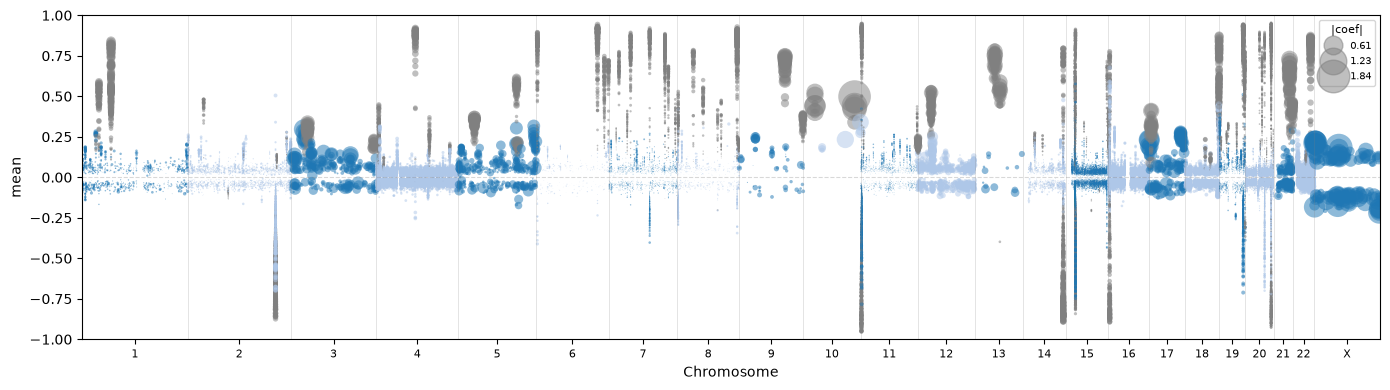

In [19]:
y = "mean"
size = "coef"
# Manhattan-style: x = genomic position (start + chr offset), y = Mat-Pat, size = abs_score

chr_len = fai.set_index('chr')['length'].to_dict()
chr_offsets = {}
offset = 0
for chrom in contr['chr'].cat.categories:
    chr_offsets[chrom] = offset
    offset += chr_len.get(chrom, 0)

contr['abs_pos'] = contr.apply(lambda row: chr_offsets[row['chr']] + row['pos'], axis=1)

size_scale = 300

fig, ax = plt.subplots(figsize=(14, 4))
for chrom in contr['chr'].cat.categories:
    subset = contr[contr['chr'] == chrom]
    # ax.scatter(subset['abs_pos'], subset['DiffMethyl'], s=subset['abs_score'] * size_scale, alpha=0.5, color=chr_colors[chrom], edgecolors='none')
    ax.scatter(subset['abs_pos'], subset[y], alpha=0.5, color=subset['color'], edgecolors='none' , s = subset[size].abs() * size_scale)

# Add vertical lines at chromosome boundaries
for chrom in chr_list:
    boundary = chr_offsets[chrom] + chr_len.get(chrom, 0)
    ax.axvline(boundary, color='gray', linestyle='-', alpha=0.3, lw=0.5)

# Chromosome labels at midpoints
chr_midpoints = {c: chr_offsets[c] + chr_len.get(c, 0) / 2 for c in chr_list}
ax.set_xticks(list(chr_midpoints.values()))
ax.set_xticklabels([c.replace('chr', '') for c in chr_midpoints.keys()], fontsize=8)
ax.set_xlim(0, offset)
ax.set_xlabel('Chromosome')
ax.set_ylabel(y)
ax.axhline(0, color='gray', linestyle='--', alpha=0.3, lw=0.8)
plt.ylim(-1, 1)

# Add size legend for coefficient
import matplotlib.lines as mlines

# Round values spanning the data range
vmin, vmax = contr[size].abs().min(), contr[size].abs().max()
legend_vals = np.linspace(vmin, vmax, 4)
legend_vals = np.round(legend_vals, 2)

handles = [mlines.Line2D([], [], marker='o', color='gray', alpha=0.5, linestyle='',
                          markersize=np.sqrt(v * size_scale), label=f'{v:.2f}')
           for v in legend_vals if v > 0]
ax.legend(handles=handles, title=f'|{size}|', loc='upper right', fontsize=7, title_fontsize=8)

plt.tight_layout()
plt.savefig(f"{figureDir}/manhattan_plot_Mat-Pat_size_cont.{mode}.{y}.pdf")
plt.show()

/tmp/ipykernel_1644873/1444055389.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().set_visible(False)


(-0.2, 0.2)

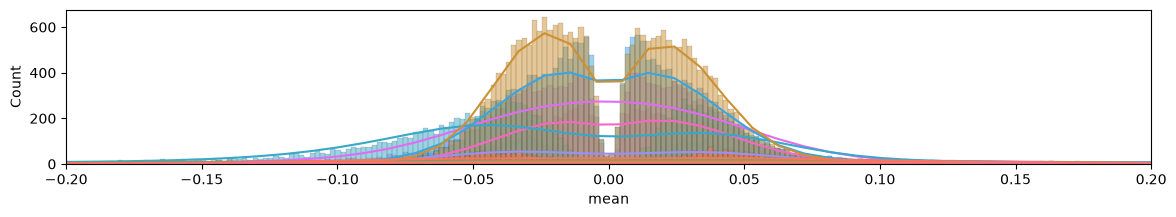

In [20]:
plt.figure(figsize=(14, 2))
sns.histplot(contr, x=y, bins=1000, kde=True, color='blue', alpha=0.5, hue='chr')

# no legend for the histogram
plt.legend().set_visible(False)

x_lim=0.2
plt.xlim(-x_lim, x_lim)

<Axes: xlabel='chr', ylabel='coef'>

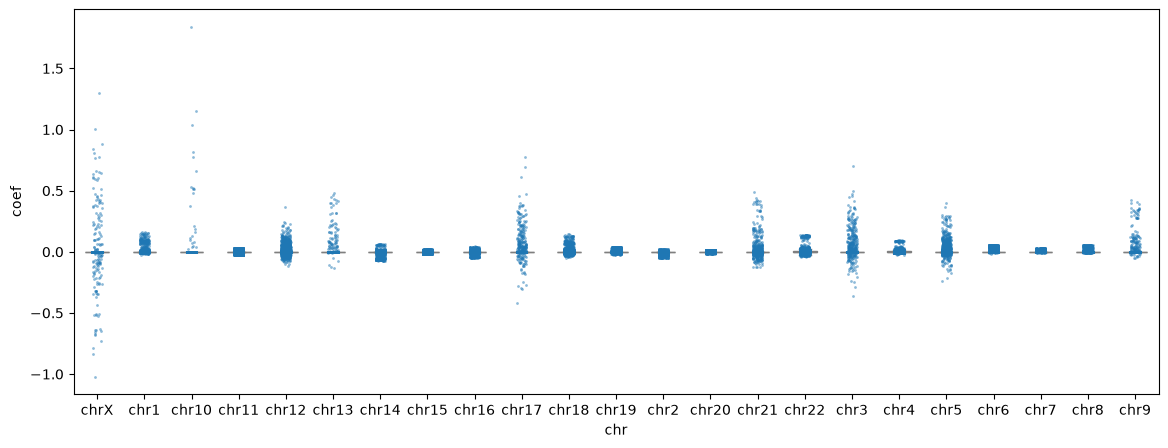

In [21]:
plt.figure(figsize=(14, 5))
y = 'coef'
sns.stripplot(data=coef_df_0, x='chr', y=y, alpha=0.5, edgecolor=None,legend=False, size=2)
sns.boxplot(data=coef_df_0, x='chr', y=y, color='lightgray', fliersize=0, width=0.5,)

In [22]:
coef_df_0.head(2)

,pos,coef,chr
0,13048,0.0,chrX
1,13101,0.0,chrX


Lower cutoff: -0.1
Upper cutoff: 0.1


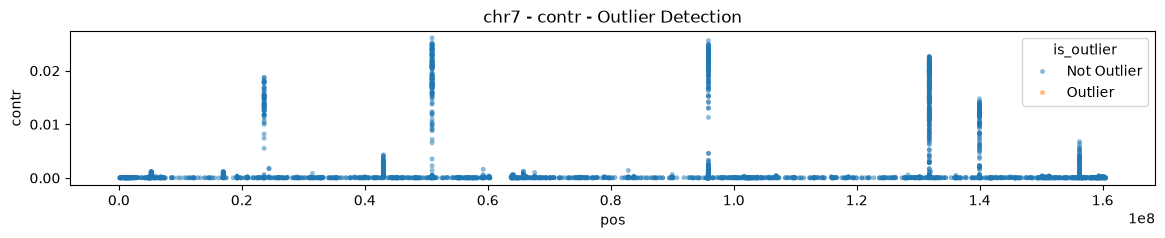

In [23]:
y = "contr"
filt = -0.1
# for chr in ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX']:
for chr in ['chr7']:
    contr_plot = contr.loc[contr['chr'] == chr].copy()

    lower = filt
    upper = -filt

    # print("Q1:", Q1)
    # print("Q3:", Q3)
    # print("IQR:", IQR)
    print("Lower cutoff:", lower)
    print("Upper cutoff:", upper)

    outliers = contr_plot[(contr_plot[y] < lower) | (contr_plot[y] > upper)]

    contr_plot['is_outlier'] = contr_plot.apply(lambda x: 'Outlier' if (x[y] < lower) or (x[y] > upper) else 'Not Outlier', axis=1)
    contr_plot['is_outlier'] = pd.Categorical(contr_plot['is_outlier'], categories=['Not Outlier', 'Outlier'], ordered=True)
    contr_plot['pos'] = contr_plot['pos'].astype(int)
    contr_plot = contr_plot.sort_values('is_outlier')
    # print("Number of outliers:", len(outliers))
    plt.figure(figsize=(14, 2))
    sns.scatterplot(data=contr_plot, x='pos', y=y, hue='is_outlier', alpha=0.5, edgecolor=None, s= 10)
    plt.title(f"{chr} - {y} - Outlier Detection")
    plt.show()

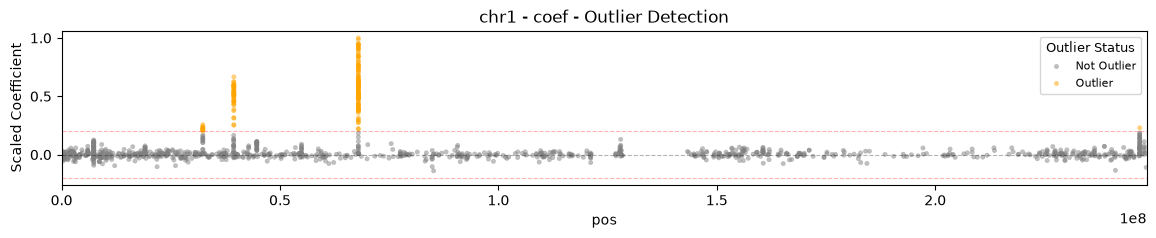

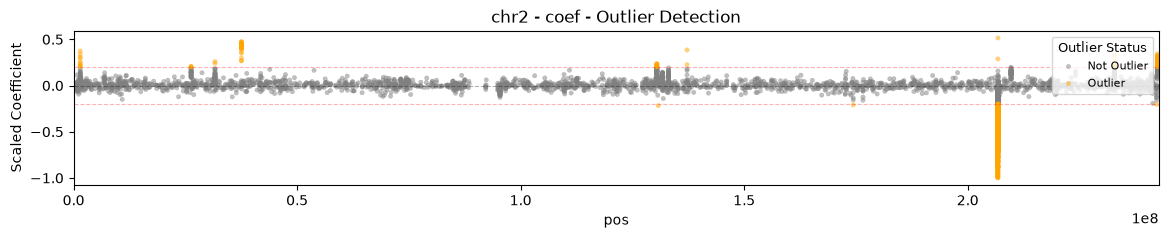

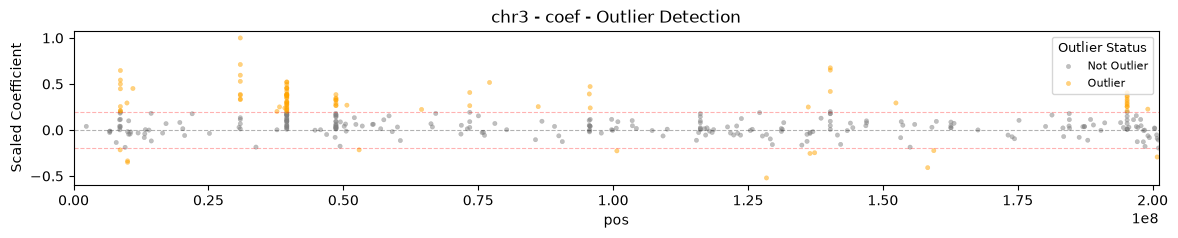

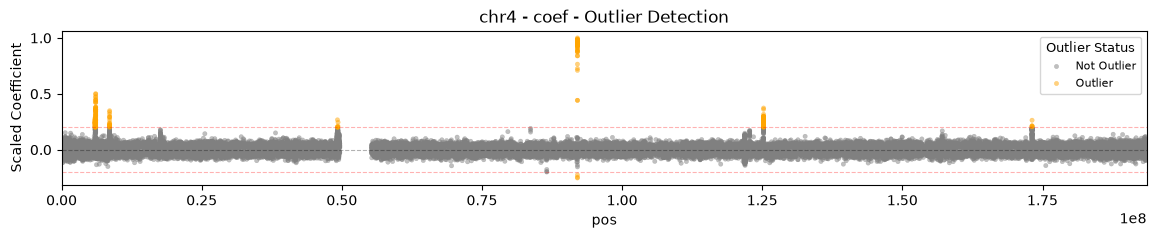

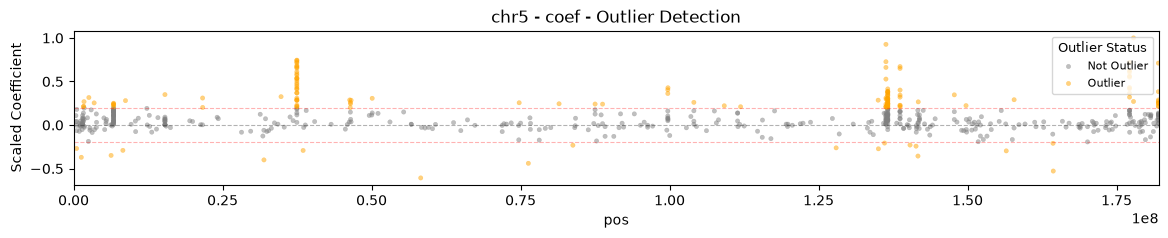

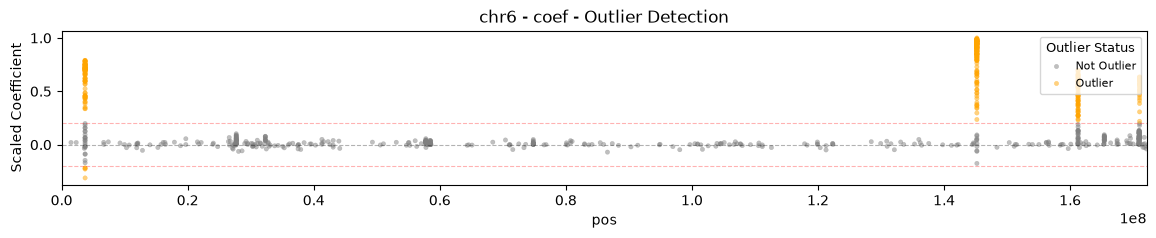

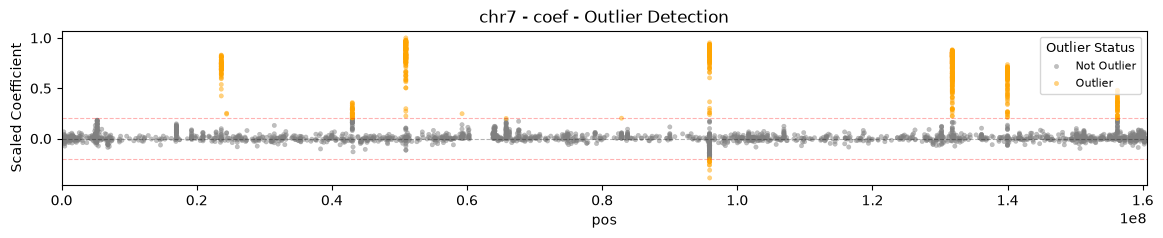

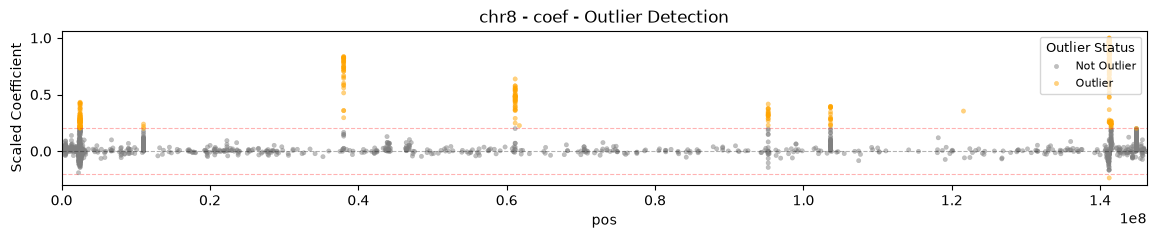

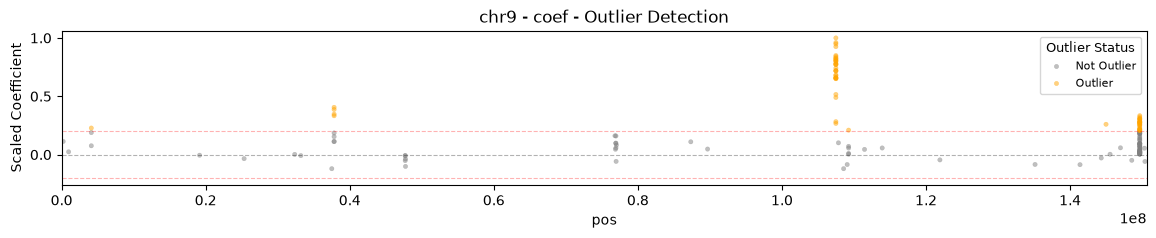

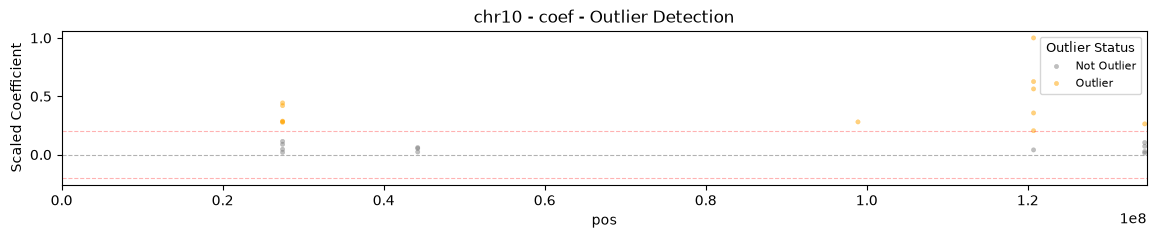

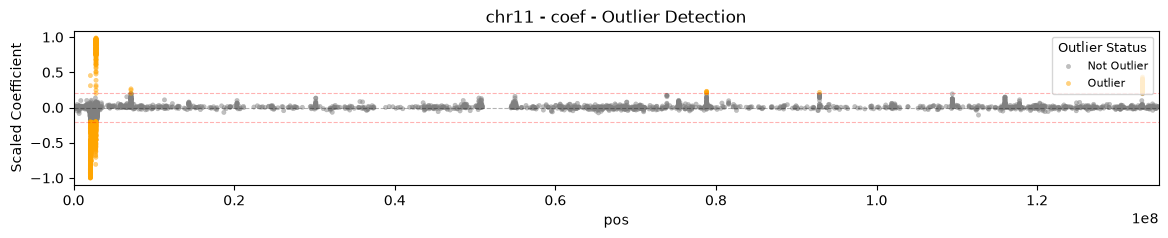

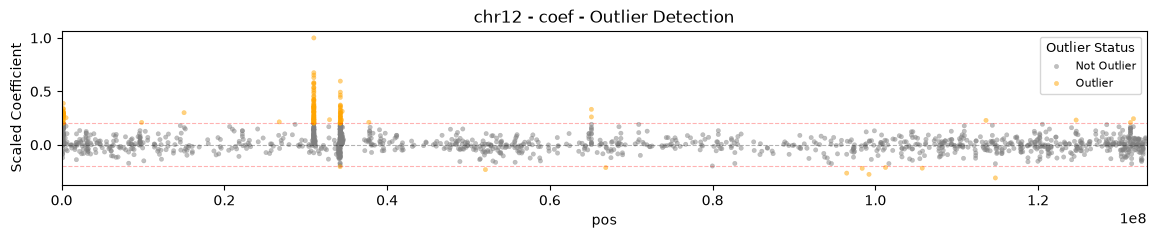

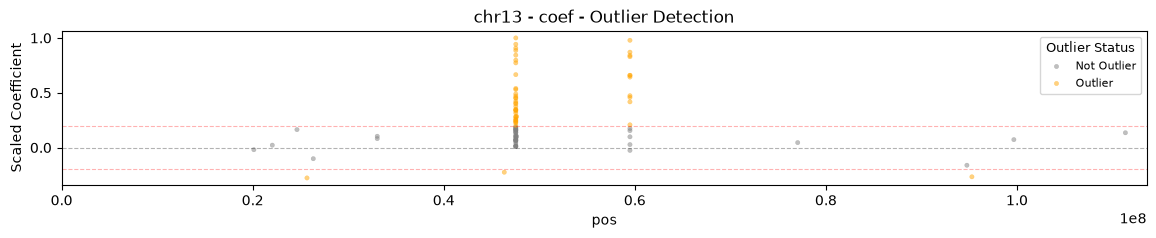

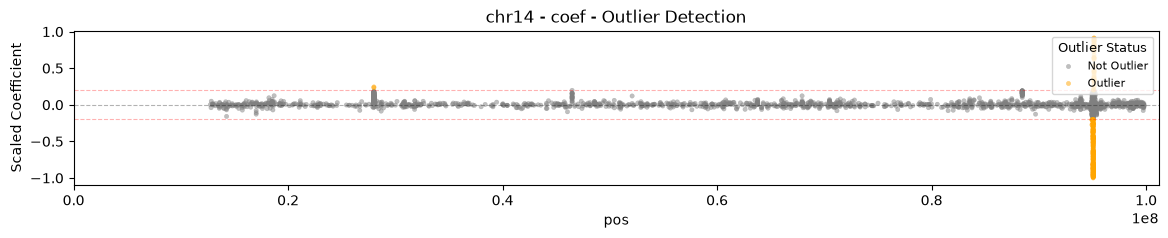

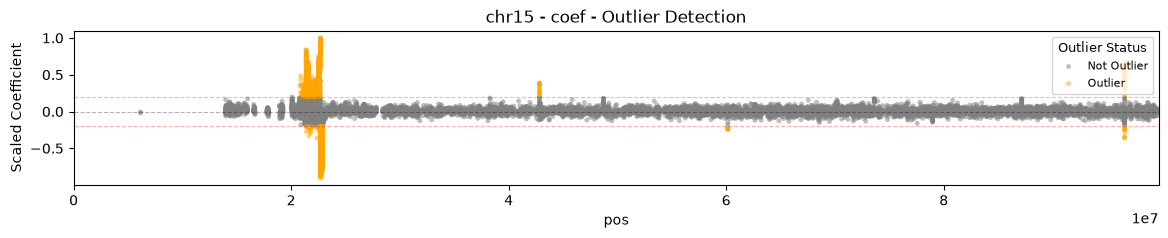

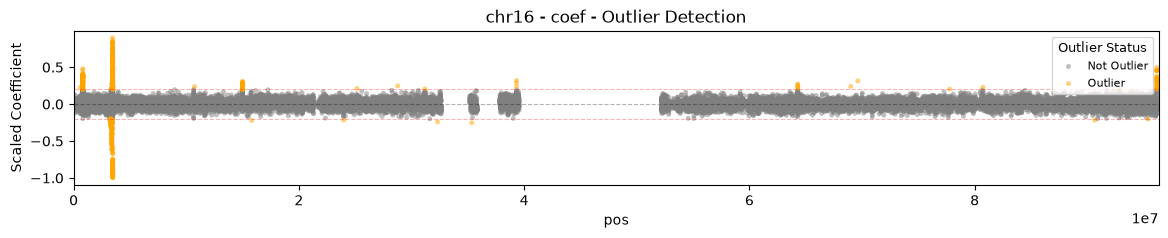

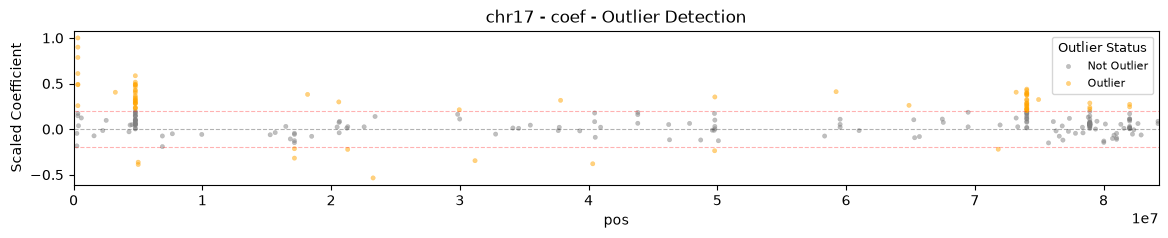

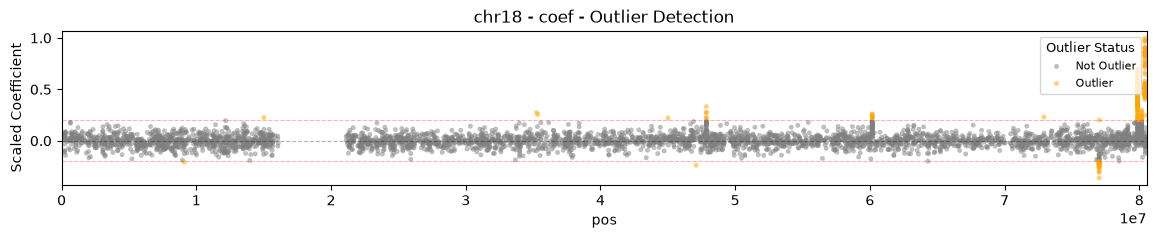

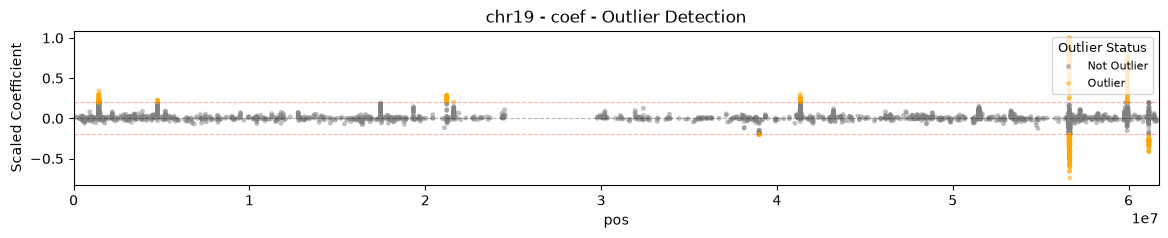

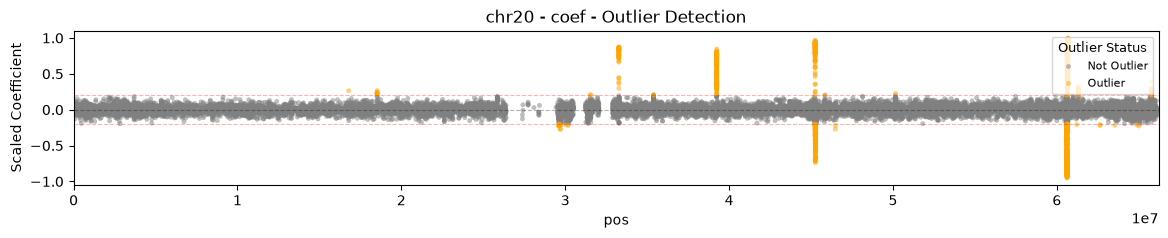

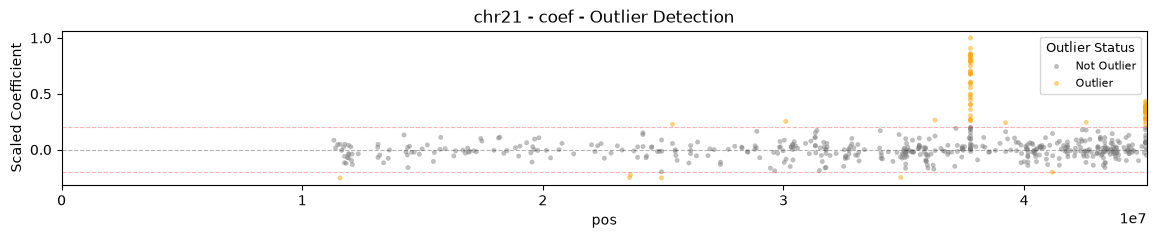

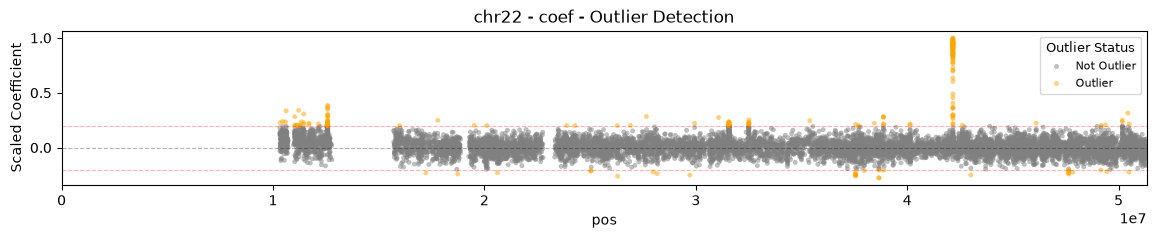

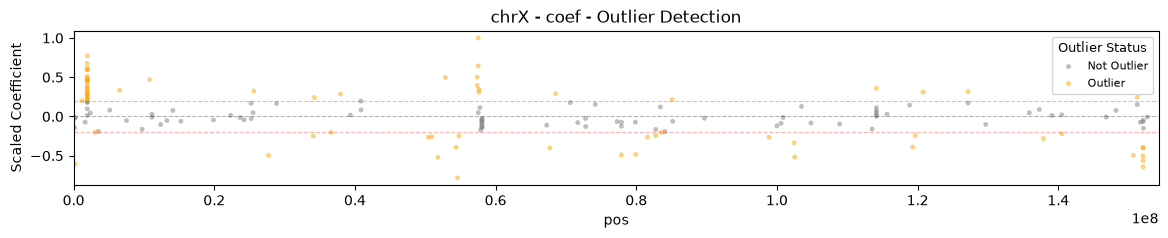

In [24]:
y = "coef"
filt=0.2
contr_plot_all= pd.DataFrame()
for chr in ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr20', 'chr21', 'chr22', 'chrX']:
#@ for chr in ['chr7']:
    contr_plot = coef_df.loc[coef_df['chr'] == chr].copy()
    #  bound to -1 to 1
    max_abs = contr_plot["coef"].abs().max()
    contr_plot["coef_scaled"] = contr_plot["coef"] / max_abs
    # contr_plot['std_coef'] = (contr_plot['coef'] - 0) / contr_plot['coef'].std()
    contr_plot['abs_coef'] = contr_plot['coef_scaled'].abs()


    Q1 = contr_plot[f"abs_{y}"].quantile(0.90)
    # Q3 = contr_plot[f"abs_{y}"].quantile(0.01)
    # IQR = Q3 - Q1

    # lower = 0 #- 1 * IQR
    upper = Q1 #+ 1 * IQR

    # print("Q1:", Q1)
    # print("Q3:", Q3)
    # print("IQR:", IQR)
    # print("Lower cutoff:", lower)
    # print("Upper cutoff:", upper)

    # outliers_pos = contr_plot[(contr_plot[y] > 0) & (contr_plot[f"abs_{y}"] > upper)]
    # outliers_neg = contr_plot[(contr_plot[y] < 0) & (contr_plot[f"abs_{y}"] > upper)]

    outliers_pos = contr_plot[(contr_plot[y] > 0) & (contr_plot[f"abs_{y}"] > filt)]
    outliers_neg = contr_plot[(contr_plot[y] < 0) & (contr_plot[f"abs_{y}"] > filt)]

    outliers_pos_set = set(outliers_pos['pos'])
    outliers_neg_set = set(outliers_neg['pos'])
    contr_plot['is_outlier'] = contr_plot.apply(lambda x: 'Outlier' if (x['pos'] in outliers_pos_set) or (x['pos'] in outliers_neg_set) else 'Not Outlier', axis=1)
    contr_plot['is_outlier'] = pd.Categorical(contr_plot['is_outlier'], categories=['Not Outlier', 'Outlier'], ordered=True)
    contr_plot['pos'] = contr_plot['pos'].astype(int)
    contr_plot = contr_plot.sort_values('is_outlier')

    contr_plot_all = pd.concat([contr_plot_all, contr_plot[['chr','pos','end','coef_scaled']].sort_values('pos')], ignore_index=True)

    plt.figure(figsize=(14, 2))
    sns.scatterplot(data=contr_plot, x='pos', y='coef_scaled', hue='is_outlier', palette={'Not Outlier': 'gray', 'Outlier': 'orange'}, alpha=0.5, edgecolor=None, s=10)
    plt.title(f"{chr} - {y} - Outlier Detection")
    plt.axhline(filt, color='red', linestyle='--', alpha=0.3, lw=0.8)
    plt.axhline(-filt, color='red', linestyle='--', alpha=0.3, lw=0.8)
    plt.axhline(0, color='black', linestyle='--', alpha=0.3, lw=0.8)
    plt.ylabel('Scaled Coefficient')
    plt.legend(title='Outlier Status', loc='upper right', fontsize=8, title_fontsize=9)
    plt.xlim(0, fai.loc[fai['chr'] == chr, 'length'].values[0])
    plt.savefig(f"{figureDir}/outlier_detection_{chr}_{y}_filt{filt}.{mode}.pdf")
    plt.show()

In [25]:
contr_plot_all.head(2)

,chr,pos,end,coef_scaled
0,chr1,332696,332697,0.025394
1,chr1,363836,363837,-0.013236


In [26]:
contr_plot_all.to_csv(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.scaled.{mode}.bed", sep='\t', header=False, index=False)

In [27]:
max_gap = 500
cutoff = 0.2

peak_df = pd.DataFrame()
for i in ['pos', 'neg']:
    print(f"Processing {i} peaks...")
    if i == 'pos':
        strong = contr_plot_all[contr_plot_all["coef_scaled"] >= cutoff].copy()
    else:
        strong = contr_plot_all[contr_plot_all["coef_scaled"] <= -cutoff].copy()

    strong = strong.sort_values(["chr", "pos"])
    strong["gap"] = strong.groupby("chr")["pos"].diff()

    strong["cluster"] = (
        (strong["gap"].isna()) |
        (strong["gap"] > max_gap)
    ).groupby(strong["chr"]).cumsum()

    peaks = (
        strong.groupby(["chr", "cluster"])
        .agg(
            start=("pos", "min"),
            end=("end", "max"),
            n_CpGs=("pos", "count"),
            max_coef=("coef_scaled", "max"),
            mean_coef=("coef_scaled", "mean")
        )
        .reset_index()
    )

    peaks = peaks[peaks["n_CpGs"] >= 3]  # Filter for clusters with at least 3 CpGs
    peaks['name'] = "Maternal" if i == 'pos' else "Paternal"
    peak_df = pd.concat([peak_df, peaks], ignore_index=True)

Processing pos peaks...
Processing neg peaks...


In [28]:
peak_df.head(2)

,chr,cluster,start,end,n_CpGs,max_coef,mean_coef,name
0,chr1,1,32328963,32329130,10,0.256663,0.225138,Maternal
1,chr1,2,39427361,39428267,40,0.666057,0.502436,Maternal


In [29]:
peak_df['itemRgb'] = peak_df['mean_coef'].apply(lambda x: '#01016f' if x < 0 else '#d8031c')
peak_df['score'] = "."
peak_df['strand'] = "."
peak_df['thickStart'] = peak_df['start']
peak_df['thickEnd'] = peak_df['end']


peak_df[['chr', 'start', 'end', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb']].to_csv(f"/home/jhu/jkim789/projects_aphill27/projects/pooch//findings/cpg_loci/elasticnet.bestmodel.allChr.rm0.strand.coef.scaled.peak.{mode}.bed", sep='\t', header=False, index=False)

In [30]:
peak_df[['chr', 'start', 'end', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb']].head(2)

,chr,start,end,name,score,strand,thickStart,thickEnd,itemRgb
0,chr1,32328963,32329130,Maternal,.,.,32328963,32329130,#d8031c
1,chr1,39427361,39428267,Maternal,.,.,39427361,39428267,#d8031c
